In [1]:
import os
import sys

r_home = r"C:\Program Files\R\R-4.5.1"
r_bin = os.path.join(r_home, "bin", "x64")

os.environ["R_HOME"] = r_home
os.environ["PATH"] = r_bin + os.pathsep + os.environ["PATH"]

r_dll_handle = os.add_dll_directory(r_bin)

import rpy2.robjects as ro

print("R:", ro.r("R.version.string")[0])
print("R_HOME:", ro.r("R.home()")[0])

R: R version 4.5.1 (2025-06-13 ucrt)
R_HOME: C:/PROGRA~1/R/R-45~1.1


In [2]:
from pathlib import Path
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.packages import importr
from rpy2.robjects.conversion import localconverter
import logging

import anndata2ri
import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro

rcb.logger.setLevel(logging.ERROR)
ro.pandas2ri.activate()
anndata2ri.activate()

%load_ext rpy2.ipython

pandas2ri.activate()
numpy2ri.activate()

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)

DeprecationWarning: 
The activate and deactivate are deprecated. To set a conversion
context check the docstring for rpy2.robjects.conversion.Converter.context.


In [3]:
sc.settings.verbosity = 3
sc.logging.print_versions()
sc.settings.set_figure_params(dpi=80, facecolor="white")

-----
anndata     0.10.9
scanpy      1.10.3
-----
PIL                 11.3.0
anndata2ri          1.3.2
asttokens           NA
colorama            0.4.6
comm                0.2.3
cycler              0.12.1
cython_runtime      NA
dateutil            3.0.0
debugpy             1.8.21
decorator           5.3.1
exceptiongroup      1.3.1
executing           2.3.0
h5py                3.14.0
igraph              1.0.0
importlib_resources NA
ipykernel           6.31.0
jedi                0.19.2
jinja2              3.1.6
joblib              1.5.3
kiwisolver          1.4.7
legacy_api_wrap     NA
leidenalg           0.12.0
llvmlite            0.43.0
markupsafe          3.0.4
matplotlib          3.9.4
mpl_toolkits        NA
natsort             8.4.0
nt                  NA
numba               0.60.0
numpy               1.26.4
packaging           26.3
pandas              2.3.3
parso               0.8.7
platformdirs        4.4.0
prompt_toolkit      3.0.52
psutil              7.2.2
pure_eval           0.

## Data Preprocessing

In [4]:
data_root = Path("data_GSE179633_SLE")
data_dirs = {
    "DLE1113E": data_root / "DLE1113E", 
    "SLE1116E": data_root / "SLE1116E"
}

In [5]:
data_dirs

{'DLE1113E': WindowsPath('data_GSE179633_SLE/DLE1113E'),
 'SLE1116E': WindowsPath('data_GSE179633_SLE/SLE1116E')}

In [6]:
adatas = []
for batch, path in data_dirs.items():
    assert path.exists(), f"Missing path: {path}"
    ad_i = sc.read_10x_mtx(path, var_names="gene_symbols", cache=True)
    ad_i.var_names_make_unique()
    ad_i.obs["sample"] = batch
    ad_i.obs_names = [f"{x}-{batch}" for x in ad_i.obs_names]
    adatas.append(ad_i)

adata = ad.concat(adatas, join="outer", label="sample", keys=list(data_dirs.keys()))
adata.layers["counts"] = adata.X.copy()
adata

... reading from cache file cache\data_GSE179633_SLE-DLE1113E-matrix.h5ad
... reading from cache file cache\data_GSE179633_SLE-SLE1116E-matrix.h5ad


AnnData object with n_obs × n_vars = 9032 × 36601
    obs: 'sample'
    layers: 'counts'

In [7]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].head()

,total_counts,n_genes_by_counts,pct_counts_mt
AAACCCAAGAAACCAT-1-DLE1113E,71374.0,7765,1.651862
AAACCCAAGGAACCAT-1-DLE1113E,3790.0,1612,1.187335
AAACCCAGTCTTCAAG-1-DLE1113E,1822.0,925,0.933041
AAACCCAGTTGCATCA-1-DLE1113E,3291.0,1326,0.546946
AAACCCATCACGAGGA-1-DLE1113E,558.0,134,67.025085


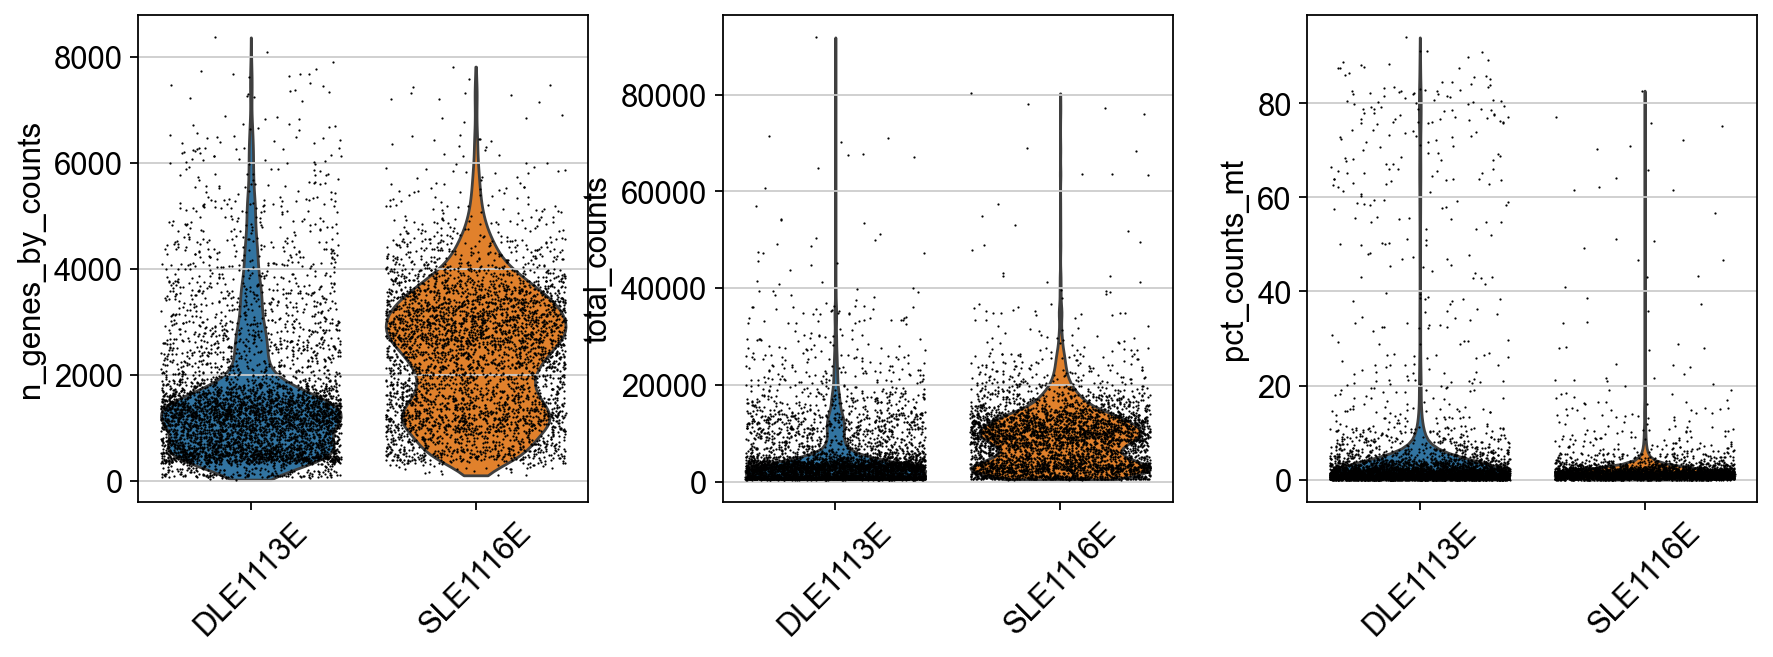

In [8]:
sc.pl.violin(
    adata, 
    keys=["n_genes_by_counts", "total_counts", "pct_counts_mt"], 
    groupby="sample", 
    rotation=45, 
    jitter=0.4, 
    multi_panel=True, 
    save="_qc_violin_per_sample.png"
)

In [9]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

filtered out 143 cells that have less than 200 genes expressed
filtered out 13647 genes that are detected in less than 3 cells


In [10]:
min_genes = 200
max_genes = None
max_pct_mt = 10.0

qc_mask = np.ones(adata.n_obs, dtype=bool)
if min_genes is not None:
    qc_mask &= adata.obs["n_genes_by_counts"] >= min_genes
if max_genes is not None:
    qc_mask &= adata.obs["n_genes_by_counts"] <= max_genes
if max_pct_mt is not None:
    qc_mask &= adata.obs["pct_counts_mt"] <= max_pct_mt

adata_filt = adata[qc_mask].copy()
print(f"After QC: {adata_filt.n_obs} / {adata.n_obs}")

After QC: 8559 / 8889


## Doublet Removal

In [11]:
from rpy2.rinterface_lib import callbacks
import sys
callbacks.consolewrite_print = lambda x: sys.stdout.write(x)
callbacks.consolewrite_warnerror = lambda x: sys.stdout.write(x)

ro.r('''
library(SingleCellExperiment)
library(scDblFinder)
run_scdbl <- function(counts_mat, seed=777) {
    set.seed(seed)
    sce <- SingleCellExperiment(list(counts = counts_mat))
    sce <- scDblFinder(sce, verbose=TRUE)
    data.frame(
        scDblFinder_score = sce$scDblFinder.score, 
        scDblFinder_class = as.character(sce$scDblFinder.class), 
        stringsAsFactors = FALSE
    )
}
''')

adata_filt.obs["scDblFinder_score"] = np.nan
adata_filt.obs["scDblFinder_class"] = pd.Categorical([None]*adata_filt.n_obs, categories=["singlet", "doublet"])

for b in sorted(adata_filt.obs["sample"].unique()):
    ad_b = adata_filt[adata_filt.obs["sample"] == b]
    print(f"[scDblFinder] batch={b}, cells={ad_b.n_obs}")
    
    data_mat = ad_b.X.T
    if not isinstance(data_mat, np.ndarray):
        import scipy.sparse as sp
        if sp.issparse(data_mat):
            data_mat = data_mat.A
    
    with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
        ro.globalenv["counts_mat"] = data_mat
        df = ro.r("run_scdbl(counts_mat)")
        df = pd.DataFrame(df)
    
    adata_filt.obs.loc[ad_b.obs_names, "scDblFinder_score"] = pd.to_numeric(df["scDblFinder_score"], errors="coerce")
    adata_filt.obs.loc[ad_b.obs_names, "scDblFinder_class"] = pd.Categorical(df["scDblFinder_class"].astype(str), categories=["singlet", "doublet"])

R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F22A7CF40>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F24DF9EC0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F22A3FAC0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xb4 in position 1: invalid start byte <traceback object at 0x0000015F228FC100>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F22A3FAC0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <tra

The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, rowRanks,
    rowSdDiffs, rowSds, rowSums2, rowTabulates, rowVarDiffs, rowVars,
    rowWeightedMads, rowWeightedMeans, rowWeightedMedians,
    rowWeightedSds, rowWeig

R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xb4 in position 1: invalid start byte <traceback object at 0x0000015F256F3280>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F20EBA600>


The following object is masked from 'package:utils':

    findMatches

The following objects are masked from 'package:base':

    expand.grid, I, unname



R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xb4 in position 1: invalid start byte <traceback object at 0x0000015F24DF9B00>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F24DF9B00>


The following object is masked from 'package:grDevices':

    windows



R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc7 in position 0: invalid continuation byte <traceback object at 0x0000015F3C79AB00>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xb4 in position 1: invalid start byte <traceback object at 0x0000015F228FC100>


Welcome to Bioconductor

    Vignettes contain introductory material; view with
    'browseVignettes()'. To cite Bioconductor, see
    'citation("Biobase")', and for packages 'citation("pkgname")'.

The following object is masked from 'package:MatrixGenerics':

    rowMedians

The following objects are masked from 'package:matrixStats':

    anyMissing, rowMedians



R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation byte <traceback object at 0x0000015F24DF9B00>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation byte <traceback object at 0x0000015F20EBA600>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation byte <traceback object at 0x0000015F20D783C0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation byte <traceback object at 0x0000015F20EBA600>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation byte <traceback object at 0x0000015F20D783C0>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xc6 in position 3: invalid continuation by

In addition: Warning messages:
[scDblFinder] batch=DLE1113E, cells=4665
Creating ~3732 artificial doublets...
Dimensional reduction
Evaluating kNN...
Training model...
iter=0, 627 cells excluded from training.
iter=1, 681 cells excluded from training.
iter=2, 664 cells excluded from training.
Threshold found:0.471
330 (7.1%) doublets called
[scDblFinder] batch=SLE1116E, cells=3894
Creating ~3116 artificial doublets...
Dimensional reduction
Evaluating kNN...
Training model...
iter=0, 388 cells excluded from training.
iter=1, 463 cells excluded from training.
iter=2, 479 cells excluded from training.
Threshold found:0.678
261 (6.7%) doublets called


In [12]:
adata_filt.obs["scDblFinder_class"].value_counts(dropna=False)

scDblFinder_class
singlet    7968
doublet     591
Name: count, dtype: int64

In [13]:
keep = adata_filt.obs["scDblFinder_class"] == "singlet"
adata_integrated = adata_filt[keep].copy()
print(f"After doublet removal: {adata_integrated.n_obs} / {adata_filt.n_obs}")

After doublet removal: 7968 / 8559


In [14]:
adata_integrated.layers["counts"] = adata_integrated.X.copy()

In [15]:
sc.pp.normalize_total(adata_integrated, target_sum=1e4)
sc.pp.log1p(adata_integrated)

normalizing counts per cell
    finished (0:00:00)


In [16]:
sc.pp.highly_variable_genes(
    adata_integrated,
    layer="counts",
    n_top_genes=2000,
    min_mean=0.0125,
    max_mean=3,
    min_disp=0.5,
    flavor="seurat_v3", 
    batch_key="sample"
)

extracting highly variable genes
--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


In [17]:
adata_integrated.layers["scaled"] = adata_integrated.X.toarray()
sc.pp.regress_out(adata_integrated, ["total_counts", "pct_counts_mt"], layer="scaled")
sc.pp.scale(adata_integrated, max_value=10, layer="scaled")

regressing out ['total_counts', 'pct_counts_mt']
    finished (0:02:03)


## Principal Component Analysis (PCA)

In [18]:
sc.tl.pca(adata_integrated, n_comps=50, svd_solver="arpack", use_highly_variable=True)

computing PCA
    with n_comps=50


C:\Users\psj89\anaconda3\envs\scrna_multi\lib\site-packages\scanpy\preprocessing\_pca.py:377: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


    finished (0:00:00)


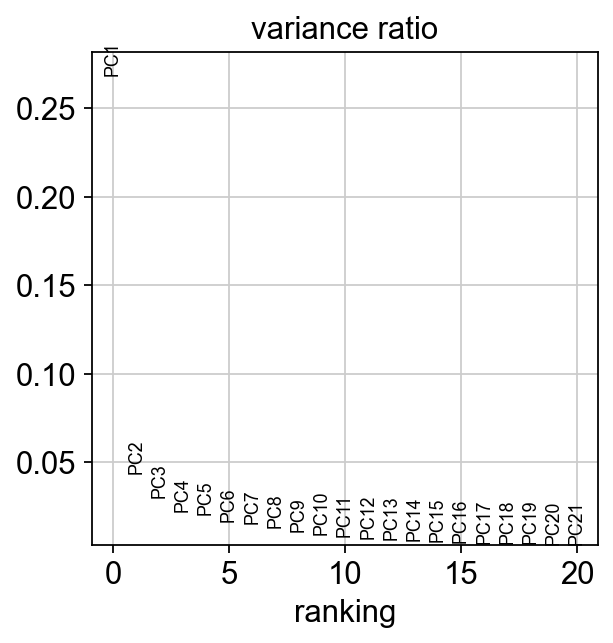

In [19]:
sc.pl.pca_variance_ratio(adata_integrated, n_pcs=20)

## Data integration using Harmony

In [20]:
import scanpy.external as scext
scext.pp.harmony_integrate(adata_integrated, key="sample", basis="X_pca")

2026-10-30 10:34:42,977 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-30 10:34:46,324 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-30 10:34:46,353 - harmonypy - INFO - Iteration 1 of 10
2026-10-30 10:34:47,124 - harmonypy - INFO - Iteration 2 of 10
2026-10-30 10:34:47,886 - harmonypy - INFO - Iteration 3 of 10
2026-10-30 10:34:48,646 - harmonypy - INFO - Converged after 3 iterations


In [21]:
adata_integrated.obsm["X_pca_harmony"] = adata_integrated.obsm["X_pca_harmony"].astype("float32")

## Computing the neighborhood graph

In [22]:
sc.pp.neighbors(adata_integrated, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=10, metric='euclidean')

computing neighbors


C:\Users\psj89\anaconda3\envs\scrna_multi\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:05)


## UMAP

In [23]:
sc.tl.umap(adata_integrated, min_dist=0.3)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:06)


## Graph-based Clustering

In [24]:
sc.tl.leiden(
    adata_integrated,
    resolution=0.5,
    random_state=0,
    flavor="leidenalg",
    n_iterations=2,
    directed=False,
)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


C:\Users\psj89\AppData\Local\Temp\ipykernel_3404\1882981742.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


In [25]:
adata_integrated.obs["leiden"] = adata_integrated.obs["leiden"].copy()
adata_integrated.uns["leiden"] = adata_integrated.uns["leiden"].copy()
adata_integrated.obsm["X_umap"] = adata_integrated.obsm["X_umap"].copy()

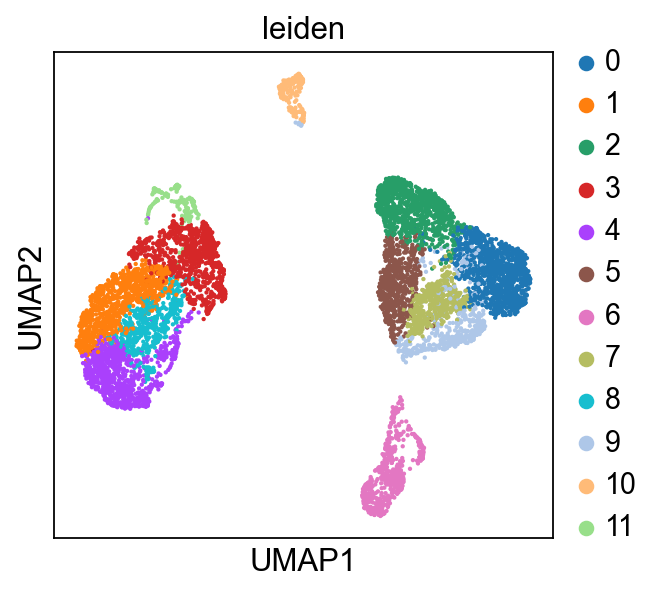

In [26]:
sc.pl.umap(adata_integrated, color=["leiden"])

## Finding marker genes

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


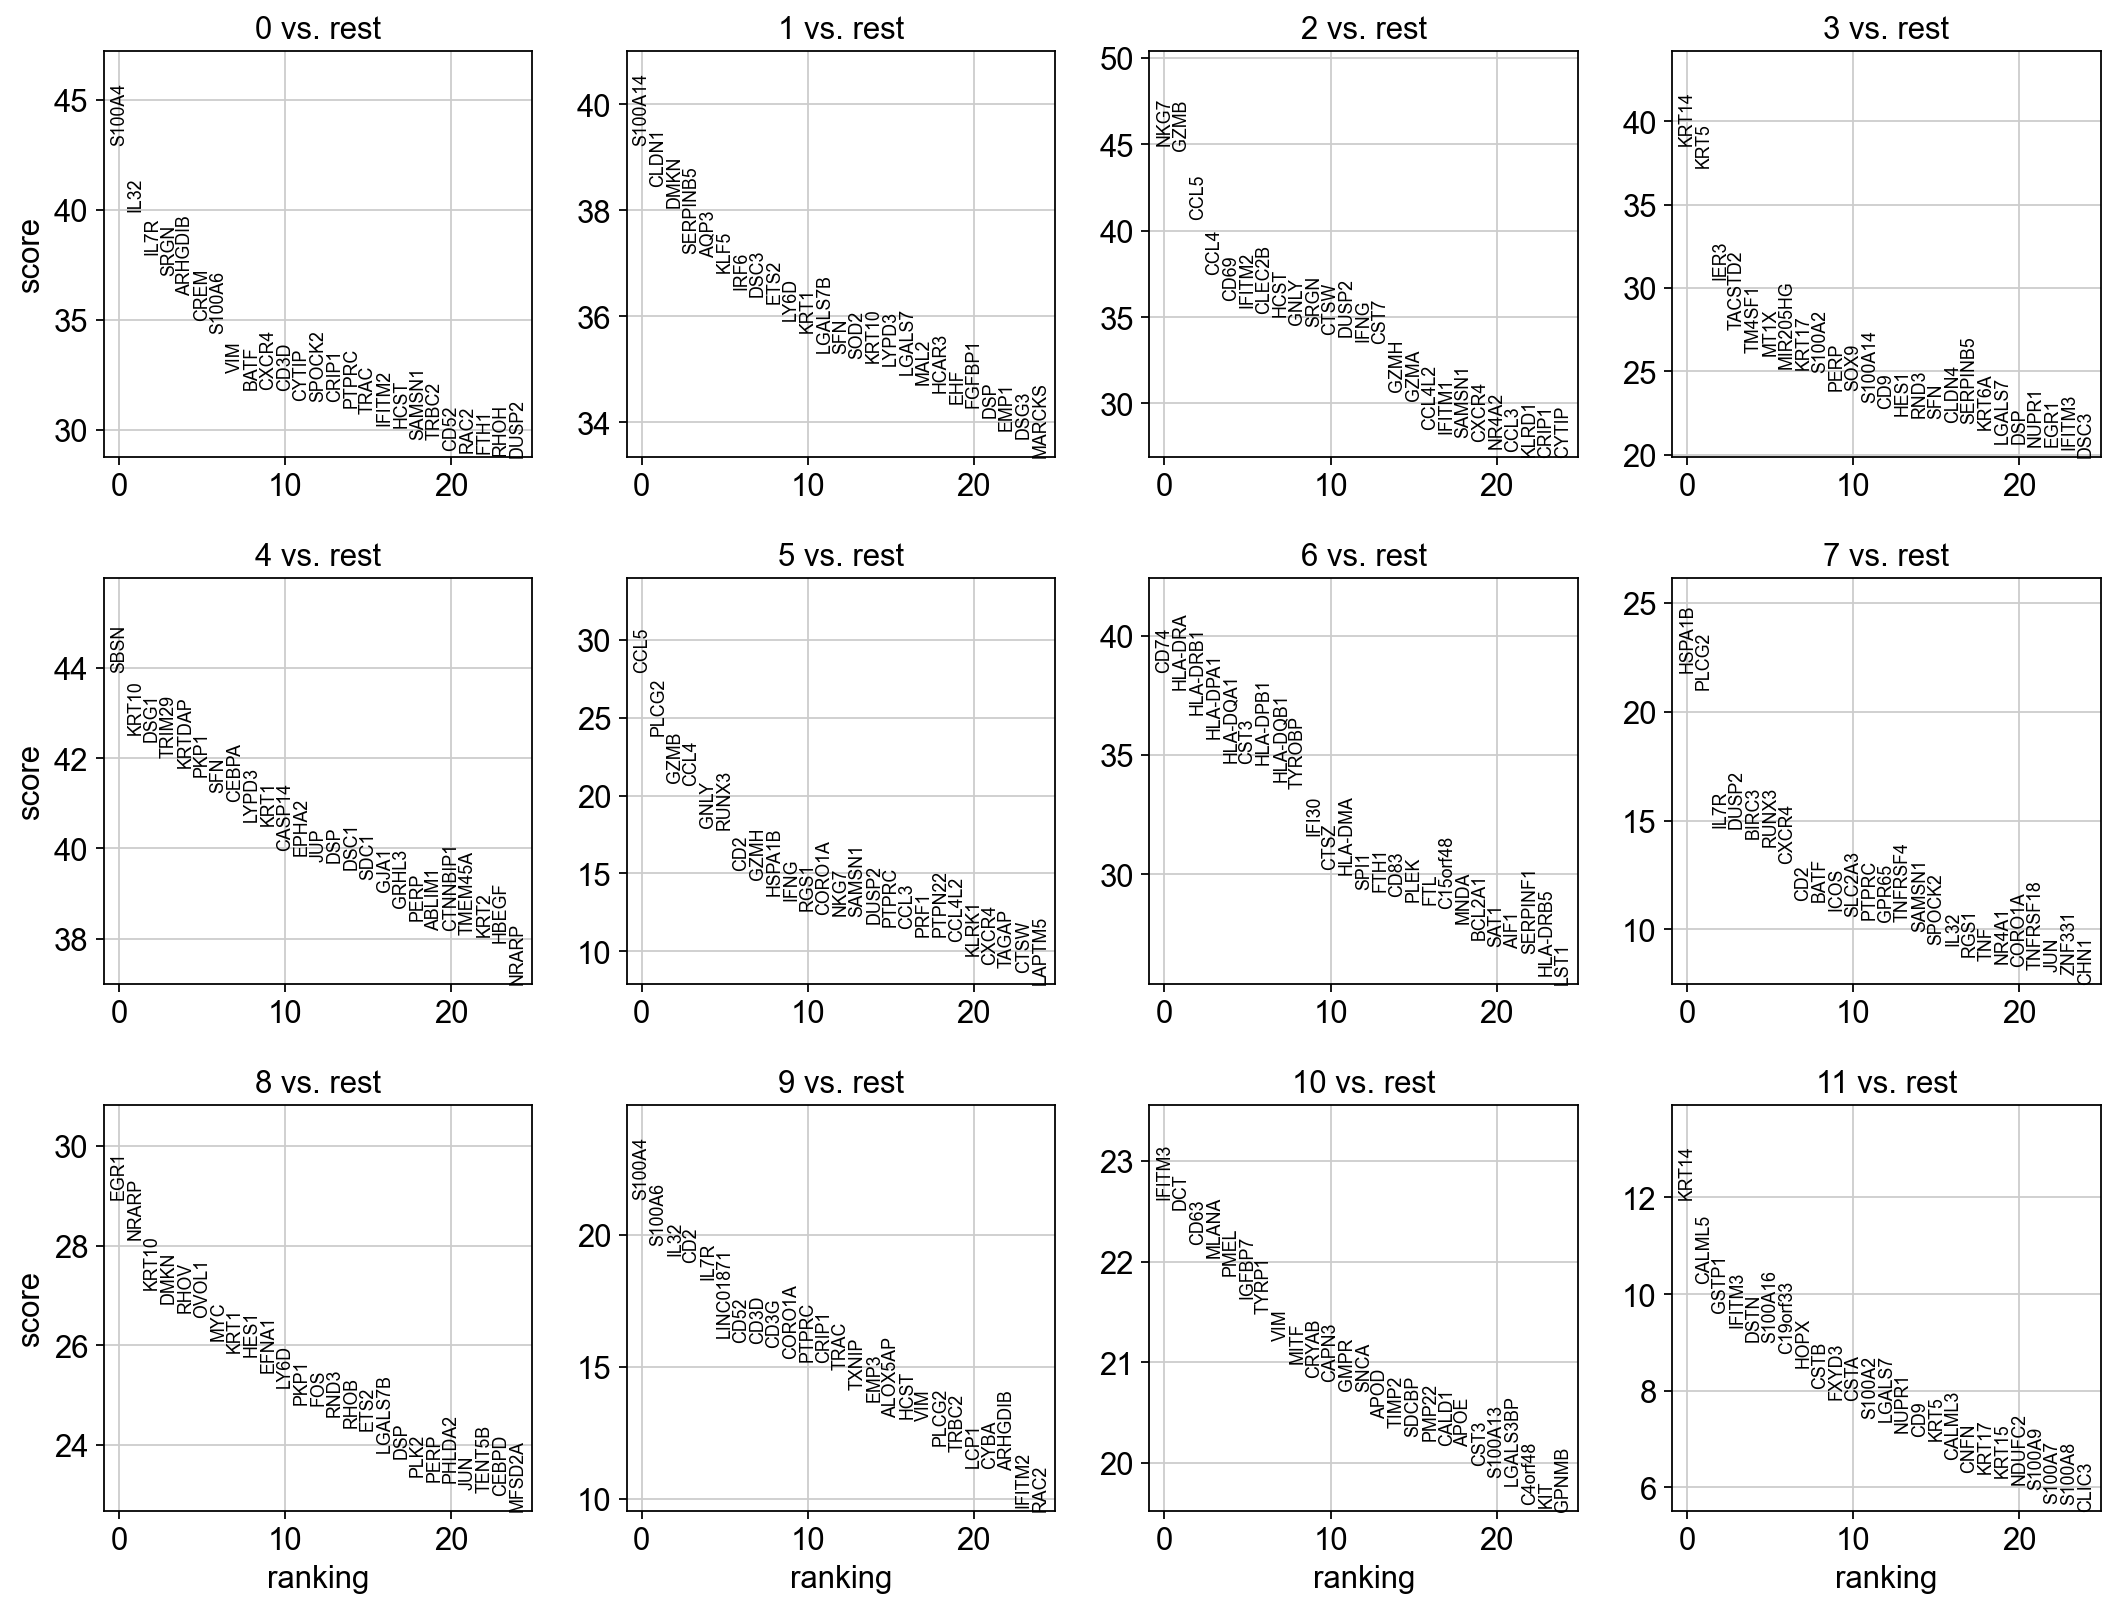

In [27]:
sc.tl.rank_genes_groups(adata_integrated, "leiden", mask_var="highly_variable", method="wilcoxon")
sc.pl.rank_genes_groups(adata_integrated, n_genes=25, sharey=False)

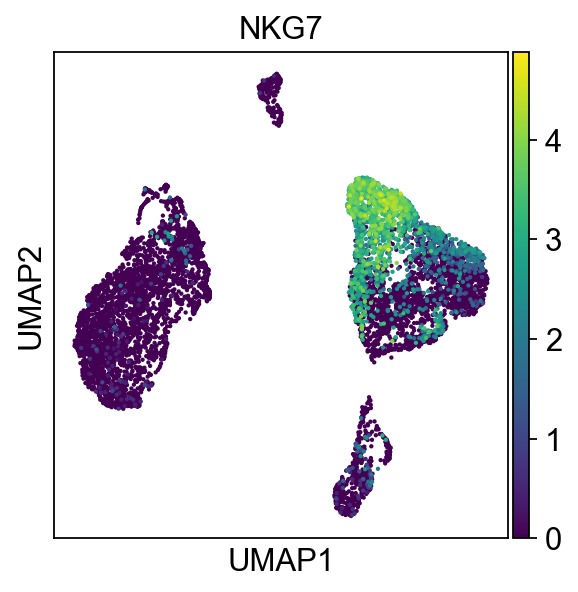

In [28]:
sc.pl.umap(adata_integrated, color=["NKG7"])

## Cell type annotation

In [ ]:
# (Write your code)

## Differentially expressed genes

In [ ]:
# (Write your code)